<center>

### **Ilum Escola de Ciência**
#### Bacharelado em Ciência e Tecnologia

<br>

### **Modelos de Aprendizados de Máquina para a Predição de Toxicidade de Nanocompostos em Tumores**
#### Trabalho Final da Disciplina de Aprenzidado de Máquina

<br>

**Aluna:** Mariana B. Cavalcanti  
**Professor:** Prof. Dr. Daniel R. Cassar 

<br>

Campinas - SP  
2026

<center>


### 1. Introdução

Nanocompostos têm sido cada vez mais utilizados em áras como biomedicina e industria. Algumas propriedades que os tornam úteis, como a elevada área de superfície e a reatividade, támbem podem causar efeitos adversos em sistemas biológicos. Avaliar a toxicidade de cada nanomaterial por ensaios experimentais é custoso, e há milhares de combinações possíveis de composição, tamanho e revestimento. Por isso, métodos computacionais capazes de estimar a toxidade a partir de propriedades já conhecidas tem despertado grande interesse na comunidade científica.

A toxicidade de uma nanopartícula não depende apenas do material. Ela resulta da interações entre características, como composição química, diâmetro e revestimento, e condições de ensaio, como a linhagem celular, a concentração e o tempo de exposição. Nesse sentido, esse tipo de estrutura necessita de atenção, devido que as medidas de um mesmo experimento são muito parecidas entre si, e as de um mesmo material compartilham as mesmas propriedades. Logo, se esses grupos de dados forem divididos entre treino e teste, o modelo é avaliado em situações que já conhece, e o seu desempenho fica superestimado.

Nesse trabalho, foi formulado a predição da toxicidade como um problema de classificação binária (tóxico ou não tóxico) sobre um conjunto de 2.765 medidas, referentes a 25 nanopartículas e 621 experimentos distintos. O conjunto de dados utilizado foi compilado por Liu et al.(2025) e publicado no artigo “Interpretable machine learning models for predicting the antitumor effects of metal and metal oxide nanomaterials” (RSC Advances, v. 15, p. 17036–17048, DOI: 10.1039/d5ra02309b). Os autores combinaram dados de toxicidade publicados, extraídos de 152 artigos, com descritores obtidos por cálculos de química quântica, reunindo 39 descritores. Foi comparado cinco algoritmos de aprendizado de máquina, sendo eles os k vizinhos mais próximos, a regressão logística, a árvore de decisão, a floresta aleatória e o gradient boosting, tendo como referência um classificador baseline. Em cada um, o pré-processamento (normalização e codificação das variávies categóricas) e os hiperparâmetros foram otimizados com o Optuna, usando o PR-AUC como métrica, por ser adequada com dados desbalenceados, já que apenas cerca de $25$% das medidas é tóxico.



### 2. Configuração de Ambiente e Dados

Inicialmente, é necessário importar algumas bibliotecas essenciais, como o pandas e o numpy.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.preprocessing import (MaxAbsScaler, MinMaxScaler, OneHotEncoder, 
                                   OrdinalEncoder, RobustScaler, StandardScaler, 
                                   TargetEncoder, FunctionTransformer
)

from sklearn.pipeline import Pipeline

from sklearn.compose import ColumnTransformer

In [3]:
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, StratifiedKFold

from sklearn.metrics import ( confusion_matrix, accuracy_score, average_precision_score,
                             matthews_corrcoef, roc_auc_score, f1_score, recall_score, precision_score
                             )
import optuna 

from optuna import create_study

optuna.logging.set_verbosity(optuna.logging.WARNING)

import optuna.visualization as vis 


In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

In [5]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

In [6]:
from pathlib import Path

PASTA_FIGURAS = Path(r"C:\JupyterLab\2 semestre - 2026\Aprendizado de Máquina\Entregas\Repositório_no_github\Trabalho_final_de_machine_learning\Imagens")

Nesse sentido, os dados foram processados a partir da biblioteca pandas, que os transformam em um DataFrame, nomeado como dados_literatura.

In [7]:
dados_literatura = pd.read_csv('nanotox_literatura.csv', sep=',')

### 3. Análise Exploratória dos Dados

#### 3.1 Visão Geral 

In [8]:
resumo_literatura = pd.DataFrame({
    'tipo' : dados_literatura.dtypes.astype(str),
    'n_unicos' : dados_literatura.nunique(),
    'ausentes' : dados_literatura.isna().sum(),
    'ausentes_%' : (dados_literatura.isna().mean() * 100).round(2)
})

print(resumo_literatura)

                            tipo  n_unicos  ausentes  ausentes_%
id_linha                   int64      2765         0        0.00
nanoparticula                str        25         0        0.00
revestimento                 str        32      1582       57.22
diametro_nm              float64       117         0        0.00
concentracao_uM          float64       501         0        0.00
potencial_zeta_mV        float64        77         0        0.00
linhagem_celular             str        30         0        0.00
celula_humana_animal         str         2         0        0.00
especie_celula               str         3         0        0.00
morfologia_celular           str         8         0        0.00
orgao_tecido                 str        17         0        0.00
tempo_exposicao_h          int64        20         0        0.00
ensaio                       str        18         0        0.00
indicador_ensaio             str        17         0        0.00
metrica_bioquimica       

A partir dos dados acima, foi possível perceber que alguns atributos como os descritores quânticos não estam presentes na validação externa.Nesse sentido, o atributo 'revestimento' apresentou elevada proporção de dados ausentes em ambos os conjuntos,provavelmente esses dados devem indicar 'partícula sem revestimento'. A caracterização dos atributos e o resumo dos dados está mais diretamente apresentada na tabela 1 e 2, respectivamente.

Tabela 1.Atributos do conjunto de dados de Ma et al. (2025).

| Grupo | Coluna | Descrição | Unidade | Papel |
|---|---|---|---|---|
| Condição experimental | `diametro_nm` | Diâmetro hidrodinâmico da nanopartícula em solução | nm | Atributo |
| Condição experimental | `concentracao_uM` | Dose aplicada, padronizada em µM (log10 no pré-processamento) | µM | Atributo |
| Condição experimental | `potencial_zeta_mV` | Carga de superfície da nanopartícula | mV | Atributo |
| Condição experimental | `tempo_exposicao_h` | Duração do contato com as células | h | Atributo |
| Condição experimental | `revestimento` | Cobertura ou grupo funcional da superfície | – | Atributo |
| Condição experimental | `linhagem_celular` | Linhagem tumoral usada no ensaio | – | Atributo |
| Condição experimental | `ensaio` | Método de viabilidade celular (MTT, CCK8, LDH etc.) | – | Atributo |
| Identificação | `nanoparticula` | Material da nanopartícula (25 valores) | – | Grupo da validação |
| Identificação | `id_experimento` | Combinação única de nanopartícula, revestimento, tamanho, potencial zeta, linhagem, ensaio e tempo | – | Grupo da validação |
| Alvo | `toxico` | 1 = tóxico (viabilidade celular < 50%), 0 = não tóxico | – | Alvo |
| Molecular | `chi` | Eletronegatividade do metal (χ) | – | Atributo |
| Molecular | `soma_chi` | Soma das eletronegatividades dos metais no óxido (Σχ) | – | Atributo |
| Molecular | `n_oxigenio_por_soma_chi` | Átomos de oxigênio por unidade de Σχ (nO/Σχ) | – | Atributo |
| Molecular | `n_metal` | Número de átomos de metal | – | Atributo |
| Molecular | `n_oxigenio` | Número de átomos de oxigênio | – | Atributo |
| Molecular | `estado_oxidacao` | Carga do cátion metálico no óxido (q) | – | Atributo |
| Molecular | `massa_molar` | Massa molecular da fórmula (MW) | g/mol | Atributo |
| Quântico | `HOMO` | Energia do orbital ocupado mais alto; tendência a doar elétrons | eV | Atributo |
| Quântico | `LUMO` | Energia do orbital vazio mais baixo; tendência a aceitar elétrons | eV | Atributo |
| Quântico | `Eg` | Gap entre LUMO e HOMO; gap menor indica maior reatividade | eV | Atributo |
| Quântico | `HoF` | Calor de formação do cluster | – | Atributo |
| Quântico | `CA` | Área de superfície no modelo de solvatação COSMO | – | Atributo |
| Quântico | `NFL` | Número de níveis (orbitais) ocupados | – | Atributo |
| Quântico | `Pol` | Polarizabilidade; resposta da nuvem eletrônica a campos externos | – | Atributo |
| Quântico | `massa_molecular_calc` | Massa do cluster usado no cálculo | g/mol | Atributo |
| Quântico | `CV` | Volume no modelo COSMO | – | Removida (redundante com `CA`) |
| Quântico | `IP` | Potencial de ionização | eV | Removida (redundante com `HOMO`) |
| Quântico | `TX` | Eletronegatividade do cluster (Tχ) | – | Removida (redundante com `HOMO` e `LUMO`) |
| Quântico | `eletrofilicidade` | Capacidade de aceitar elétrons de biomoléculas (ω) | – | Removida (redundante com `LUMO`) |
| Quântico | `dureza_molecular` | Resistência a deformar a nuvem eletrônica (η = Eg/2) | eV | Removida (redundante com `Eg`) |
| Quântico | `S` | Moleza, inverso da dureza | 1/eV | Removida (redundante com `Eg`) |

Tabela 2. Caracterização dos atributos presentes nos conjuntos de dados nanotox_literatura.csv.
| Característica | Dados de literatura |
|----------------|---------------------|
| Número de observações | 2.765 |
| Número de atributos | 42 |
| Tipos de nanopartículas | 25 | 
| Linhagens celulares | 30 |
| Espécies celulares | 3 |
| Valores ausentes | Apenas em revestimento (57,2%) |

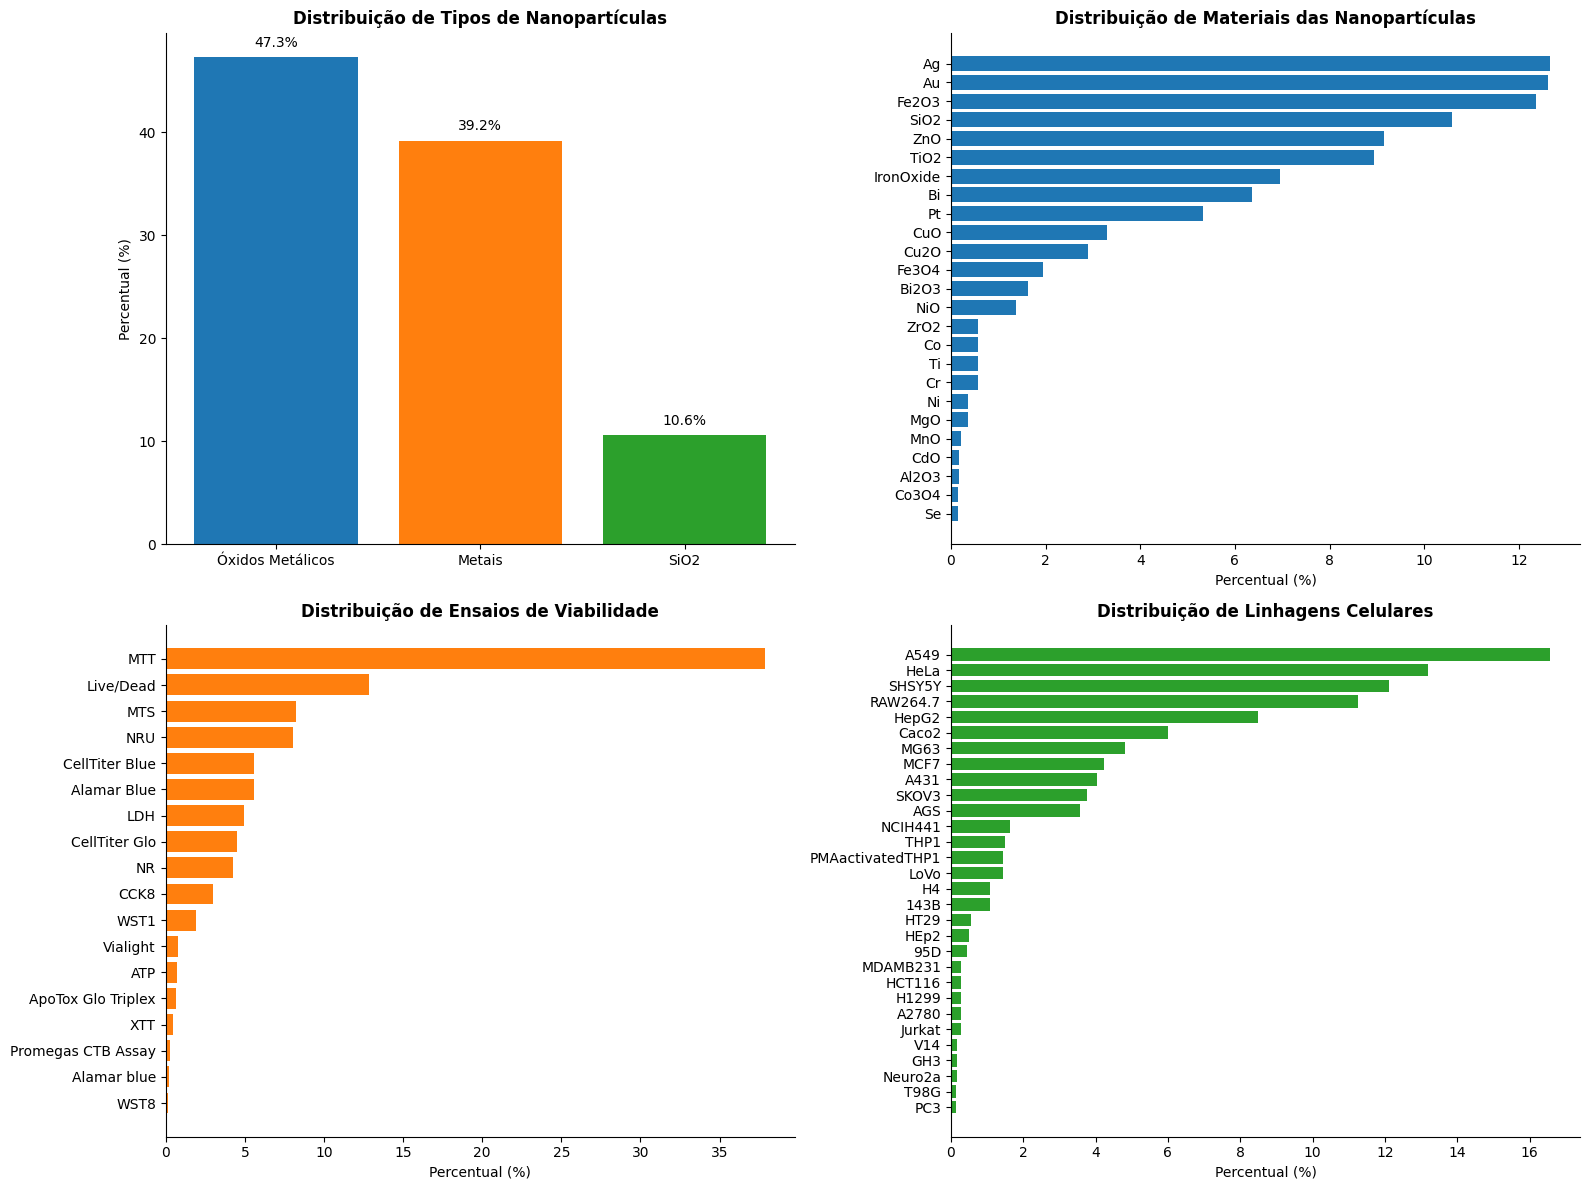

In [9]:
# Organizando os dados

# Classificação das variáveis:
 
CATEGORICAS = ["nanoparticula", "revestimento", "linhagem_celular", "celula_humana_animal", "especie_celula",
               "morfologia_celular", "orgao_tecido", "ensaio", "indicador_ensaio", "metrica_bioquimica",
               "interferencia_checada", "estab_coloidal_checada", "controle_positivo", "grupo_pontual"]

QUANTICAS = ["HoF","CA","CV","IP","HOMO","LUMO","NFL","massa_molecular_calc",
            "grupo_pontual","TX","dureza_molecular","eletrofilicidade","Eg","Pol","S"]

NUMERICAS = ["diametro_nm","concentracao_uM","potencial_zeta_mV","tempo_exposicao_h","chi","soma_chi",
             "n_oxigenio_por_soma_chi","n_metal","n_oxigenio","massa_molar","estado_oxidacao","HoF","CA","CV","IP",
             "HOMO","LUMO","NFL","massa_molecular_calc","TX","dureza_molecular","eletrofilicidade","Eg","Pol","S"]



ATRIBUTOS = CATEGORICAS + NUMERICAS

# Classificação das nanopartículas
oxidos_metalicos = [
    'Fe2O3', 'ZnO', 'TiO2', 'IronOxide', 'CuO',
    'Fe3O4', 'Bi2O3','ZrO2', 'CeO2', 'Al2O3', 
    'NiO', 'Co3O4', 'MgO', 'MnO', 'CdO'
]

metais = [
    'Ag', 'Au', 'Co', 'Pt', 
    'Bi','Ni', 'Se', 'Ti', 'Cr'
]

#Contagens e percentuais
total = len(dados_literatura)

n_oxidos_metalicos = dados_literatura['nanoparticula'].isin(oxidos_metalicos).sum()
n_metais = dados_literatura['nanoparticula'].isin(metais).sum()
n_sio2 = (dados_literatura['nanoparticula'] == 'SiO2').sum()

nanoparticulas = pd.DataFrame({
    'Tipo': ['Óxidos Metálicos', 'Metais', 'SiO2'],
    'Percentual': [
        100 * n_oxidos_metalicos / total, 
        100 * n_metais / total, 
        100 * n_sio2 / total]
})

# Materiais das nanopartículas
materiais = (
    dados_literatura['nanoparticula']
    .value_counts(normalize=True)
    .mul(100)
    .reset_index()
)
materiais.columns = ['Material', 'Percentual']

# Ensaios de viabilidade

ensaios = (
    dados_literatura['ensaio']
    .value_counts(normalize=True)
    .mul(100)
    .reset_index()
)

ensaios.columns = ['Ensaio', 'Percentual']

# Linhagens celulares

celulas = (
    dados_literatura['linhagem_celular']
    .value_counts(normalize=True)
    .mul(100)
    .reset_index()
)
celulas.columns = ['Linhagem', 'Percentual']

# Gráficos
fig, axs = plt.subplots(2, 2, figsize=(16, 12))

cores = ['#1f77b4', '#ff7f0e', '#2ca02c']
#1
axs[0, 0].bar(nanoparticulas['Tipo'],nanoparticulas['Percentual'], color=cores)
axs[0, 0].set_title('Distribuição de Tipos de Nanopartículas', fontsize=12, fontweight='bold')
axs[0,0].set_ylabel('Percentual (%)', fontsize=10)

for i, valor in enumerate(nanoparticulas['Percentual']):
    axs[0, 0].text(i, valor + 1, f'{valor:.1f}%', ha='center', fontsize=10)

#2
materiais_ordenados = materiais.sort_values(by='Percentual', ascending=True)

axs[0, 1].barh(materiais_ordenados['Material'], 
              materiais_ordenados['Percentual'], color='#1f77b4')
axs[0, 1].set_title('Distribuição de Materiais das Nanopartículas', fontsize=12, fontweight='bold')
axs[0, 1].set_xlabel('Percentual (%)', fontsize=10)

#3
ensaios_ordenados = ensaios.sort_values(by='Percentual', ascending=True)
axs[1, 0].barh(ensaios_ordenados['Ensaio'], ensaios_ordenados['Percentual'], color='#ff7f0e')
axs[1, 0].set_title('Distribuição de Ensaios de Viabilidade', fontsize=12, fontweight='bold')
axs[1, 0].set_xlabel('Percentual (%)', fontsize=10) 

#4
celulas_ordenadas = celulas.sort_values(by='Percentual', ascending=True)
axs[1, 1].barh(celulas_ordenadas['Linhagem'], celulas_ordenadas['Percentual'], color='#2ca02c')
axs[1, 1].set_title('Distribuição de Linhagens Celulares', fontsize=12, fontweight='bold')
axs[1, 1].set_xlabel('Percentual (%)', fontsize=10)

for ax in axs.flat:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(PASTA_FIGURAS / 'distribuicao_dados_literatura.png', dpi=300)

plt.show()


Esses gráficos revelam que o conjunto de dados da literatura é predominantemente composto por nanopartículas de óxidos metálicos (50,2%), seguidas por nanopartículas metálicas (39,2%) e nanopartículas de sílica (10,6%). Entre os materiais mais frequentes destacam-se Ag, Au, Fe₂O₃, SiO₂, ZnO e TiO₂. O conjunto apresenta elevada diversidade experimental, evidenciada pela ampla variação de concentrações, tamanhos de partículas e respostas biológicas observadas. Além disso, a diversidade de linhagens celulares e metodologias experimentais reforça a representatividade do conjunto para o desenvolvimento de modelos de predição de toxicidade de nanomateriais.

#### 3.2 Valores discrepantes nas variáveis numéricas

In [10]:

linhas = []

for n in NUMERICAS:
    x = dados_literatura[n]
    q1, mediana, q3 = x.quantile([0.25,0.5,0.75])
    iqr = q3 - q1 
    fora_iqr = ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()
    z = ((x - x.mean()) / x.std()).abs()
    positivos = x [x > 0]
    linhas.append({
        "variável" : n,
        "n_unicos" : x.nunique(),
        "min": x.min(),
        "mediana" : mediana,
        "max": x.max(),
        "assimetria": x.skew(),
        "pct_outliers_IQR" : 100* fora_iqr/len(x),
        "n_z_maior_4": int((z > 4).sum()),
        "ordem_magnitude" : np.log10(positivos.max()/ positivos.min() if len(positivos) else np.nan)
    })

tabela = pd.DataFrame(linhas).set_index("variável"). sort_values ("ordem_magnitude", ascending=False)
print(tabela.to_string())
escala = dados_literatura[NUMERICAS].abs().median().replace(0, np.nan)
print(f"Mediana (em módulo) mais baixa e mais alta entre as variáveis numéricas:{escala.min().round(3)} e {escala.max().round(1)}")

                         n_unicos           min      mediana           max  assimetria  pct_outliers_IQR  n_z_maior_4  ordem_magnitude
variável                                                                                                                              
concentracao_uM               501  1.660000e-20    12.571342  16644.474030    6.878557         15.298373           47        24.001162
diametro_nm                   117  1.500000e+00    29.570000    600.000000    2.174451          9.728752           20         2.602060
tempo_exposicao_h              20  1.000000e+00    24.000000    168.000000    1.554625          3.978300           20         2.225309
HoF                            24 -3.117892e+03  -573.499700   2395.876660    0.542079          0.578662            0         2.157125
eletrofilicidade               24  3.001735e-01     4.037221     24.029453    0.967701          0.578662           16         1.903372
Pol                            24  1.788142e+01   209.6

Algumas inferências foram feitas a partir das informações acima: a variável 'concentracao_uM' cobre cerca de 24 ordens de grandeza, logo será necessário utilizar o $log10$ e ainda o mínimo de $1.66e^-20$ sugere que houve algum erro na conversão de unidades em alguns experimentos; as distribuiçoes das variáveis 'diâmetro' e 'tempo de exposição' também são assimétricos o que indica a necessidade de usar a função $log10$; e a variação das medianas, em módulo, das variáveis grande justifica a necessidade de normalização para alguns algoritmos como a regressão logística.

#### 3.3 Definindo o target

Como dito anteriormente, nesse trabalho será utilizado um target binário, ou seja, será um problema de classificação.

In [11]:
dados_literatura['target'] = dados_literatura['toxico']
dados_literatura = dados_literatura.drop(columns=['toxico'])

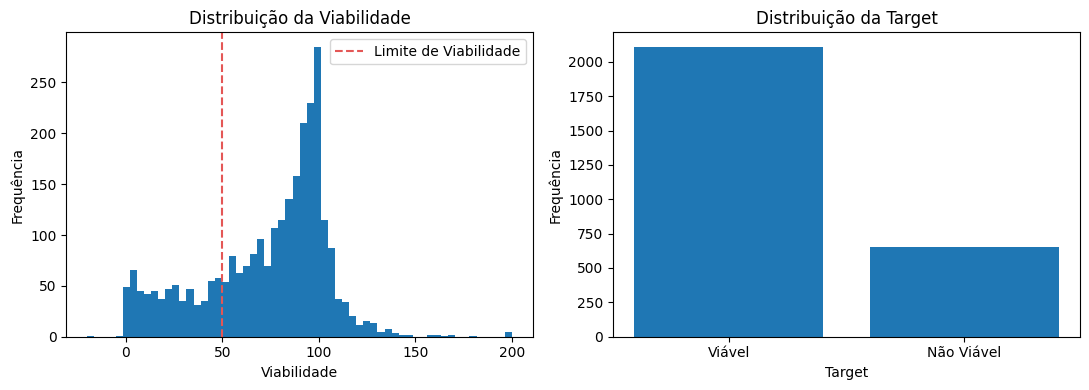

In [12]:
cont = dados_literatura['target'].value_counts().sort_index()
fig, ax = plt.subplots(1, 2,figsize=(11, 4))
ax[0].hist(dados_literatura['viabilidade_pct'].clip(-20,200), bins=60, color=['#1f77b4'])
ax[0].axvline(50, color='#E45756', linestyle='dashed', label='Limite de Viabilidade')
ax[0].set_xlabel('Viabilidade')
ax[0].set_ylabel('Frequência')
ax[0].set_title('Distribuição da Viabilidade')
ax[0].legend()

# Gráfico 2: Distribuição da Target
ax[1].bar(['Viável', 'Não Viável'], cont.values, color=['#1f77b4'])
ax[1].set_xlabel('Target')
ax[1].set_ylabel('Frequência')
ax[1].set_title('Distribuição da Target')

fig.tight_layout()
plt.savefig(PASTA_FIGURAS / 'distribuicao_viabilidade_target.png', dpi=300)
plt.show()

Assim, é possível perceber que o target deverá ser balanceado no pré-processamento para evitar possíveis outliers, e é necessário que a coluna 'viabilidade_pct' seja apagada para que não ocorra vazamentos dos dados para os modelos.

#### 3.4 Toxidade por nanopartícula

In [13]:
por_np = (
    dados_literatura.groupby('nanoparticula')
    .agg(
        n= ('target', 'size'),
        taxa_toxico = ('target', 'mean'),
        viab_mediana=('viabilidade_pct', 'median')
    )
    .sort_values('taxa_toxico', ascending=False)
)
print('Resumo por nanopartícula:')
print(por_np.round(3).to_string())

Resumo por nanopartícula:
                 n  taxa_toxico  viab_mediana
nanoparticula                                
CdO              5        1.000         2.578
Co3O4            4        0.750        33.174
Ni              10        0.500        50.493
MgO             10        0.500        62.130
Ag             350        0.497        50.568
Al2O3            5        0.400        54.026
NiO             38        0.395        64.547
ZrO2            16        0.375        54.200
Co              16        0.375        70.679
CuO             91        0.363        66.055
Cu2O            80        0.362        84.656
Pt             147        0.361        65.187
MnO              6        0.333        68.932
ZnO            253        0.324        68.577
Se               4        0.250        65.917
Bi2O3           45        0.244        67.672
SiO2           293        0.188        76.678
Fe2O3          342        0.155        88.877
Au             349        0.152        89.630
Bi      

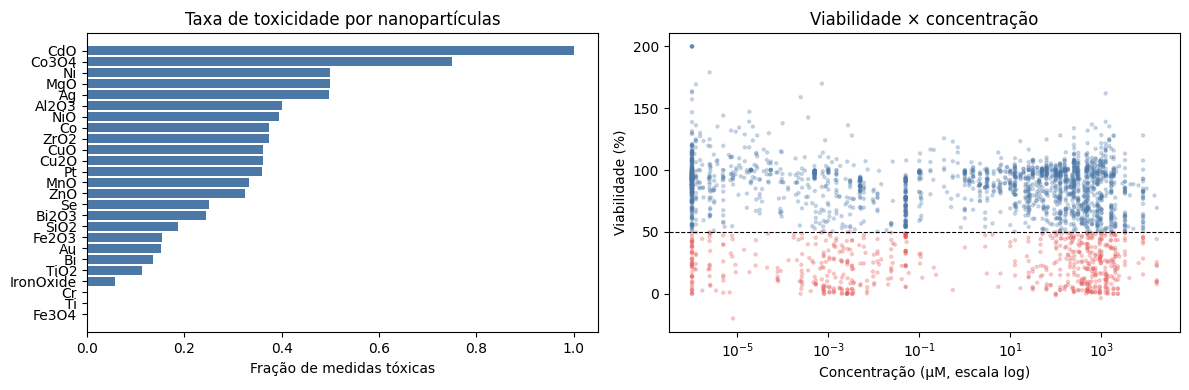

In [14]:
fig,ax = plt.subplots(1, 2, figsize = (12, 4))

ordem = por_np.sort_values('taxa_toxico').index

ax[0].barh(
    ordem,
    por_np.loc[ordem,'taxa_toxico'],
    color = '#4C78A8'
)

ax[0].set_xlabel('Fração de medidas tóxicas')
ax[0].set_title('Taxa de toxicidade por nanopartículas')

ax[1].scatter(
    dados_literatura['concentracao_uM'].clip(lower=1e-6),
    dados_literatura['viabilidade_pct'].clip(-20, 200),
    s=5,
    alpha=0.25,
    c=np.where(
        dados_literatura['target'] == 1,
        "#E45756",
        "#4C78A8"
    )
)


ax[1].set_xscale("log")
ax[1].axhline(
    50,
    color="k",
    ls="--",
    lw=0.8
)

ax[1].set_xlabel("Concentração (µM, escala log)")
ax[1].set_ylabel("Viabilidade (%)")
ax[1].set_title("Viabilidade × concentração")

plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "distribuição_viab_nano.png", dpi=300)
plt.show()

Os gráficos indicam algumas características da toxicidade das nanopartículas: as composições químicas já explica parcialmente, já que a txa medidas tóxicas varia de 0%, em Cr, Fe<sub>3</sub>O<sub>4</sub> e Ti, a 100%, em CdO; e alguns materiais, como Co<sub>3</sub>O<sub>4</sub> e CdO, tem apenas 4 ou 5 medidas, de modo que suas taxas são pouco confiáveis; e a toxicidade se concentra em poucos materiais, como Ag reúne cerca de 26% de todos os tóxicos, embora represente 12,7% do conjunto.

#### 3.5 Descritores Quânticos

In [15]:
# Descobrindo quantos valores distintos existem
print(f"Valores distintos por descritor quântico (em {len(dados_literatura)} linhas):")
print(dados_literatura[QUANTICAS].nunique().to_string())

# Cada combinação dos descritores é igual a um perfil quântico

dados_literatura["perfil_quantico"] = (
    dados_literatura.groupby(QUANTICAS, dropna=False)
      .ngroup()
)

print(
    "\nPerfis quânticos distintos:",
    dados_literatura["perfil_quantico"].nunique(),
    "| nanopartículas:",
    dados_literatura["nanoparticula"].nunique()
)

# Descobrindo se o perfil quântico é fixo por nanopartícula 

moda = (
    dados_literatura.groupby("nanoparticula")["perfil_quantico"]
      .agg(lambda s: s.mode().iloc[0])
)

fora = (
    dados_literatura["perfil_quantico"] !=
    dados_literatura["nanoparticula"].map(moda)
)

print(
    f"Linhas com o perfil típico da sua nanopartícula: {(~fora).mean():.1%} "
    f"| fora do típico: {fora.sum()} ({fora.mean():.1%})"
)

print("\nNanopartículas com mais de um perfil quântico:")

print(
    dados_literatura.groupby("nanoparticula")["perfil_quantico"]
      .nunique()
      .loc[lambda s: s > 1]
      .sort_values(ascending=False)
      .to_string()
)

Valores distintos por descritor quântico (em 2765 linhas):
HoF                     24
CA                      24
CV                      24
IP                      24
HOMO                    24
LUMO                    24
NFL                     22
massa_molecular_calc    24
grupo_pontual            9
TX                      24
dureza_molecular        24
eletrofilicidade        24
Eg                      24
Pol                     24
S                       24

Perfis quânticos distintos: 24 | nanopartículas: 25
Linhas com o perfil típico da sua nanopartícula: 94.1% | fora do típico: 163 (5.9%)

Nanopartículas com mais de um perfil quântico:
nanoparticula
Fe2O3    9
Au       5
Bi       2
Co       2
Cr       2
CuO      2
SiO2     2
Ti       2
TiO2     2
ZnO      2


Assim, os descritores químico-quânticos apresentam baixa variabilidade ao longo dos experimentos, caracterizando propriedades intrínsecas dos materiais. A maioria dos descritores avaliados apresentou 24 valores distintos em um conjunto contendo 2.765 observações e 25 nanopartículas diferentes. No entanto, as nanopartículas de Fe2O3 apresentara varios perfis distintos, logo é necessário uma verificação das possíveis causas.

In [16]:
dados_literatura.loc[
    dados_literatura["nanoparticula"] == "Fe2O3",
    QUANTICAS
].drop_duplicates()

,HoF,CA,CV,IP,HOMO,LUMO,NFL,massa_molecular_calc,grupo_pontual,TX,dureza_molecular,eletrofilicidade,Eg,Pol,S
1137,-1243.55440,408.48,633.93,10.715248,-10.715,-4.819,128,1165.8436,2,7.7670,2.9480,10.231732,5.896,52.909352,0.339213
1152,2395.87666,516.82,985.89,5.288031,-5.288,-0.329,96,1663.8720,2,2.8085,2.4795,1.590577,4.959,327.214430,0.403307
1156,-573.49970,310.43,449.67,7.776280,-7.776,-0.290,170,1590.9080,5,4.0330,3.7430,2.172734,7.486,115.190620,0.267165
1209,-77.49302,435.09,733.47,10.555741,-9.069,-4.760,108,1267.8136,2,6.9145,2.1545,11.095454,4.309,361.025102,0.464145
1285,1274.31384,543.40,1045.94,7.872196,-7.872,-5.899,44,1053.8000,8,6.8855,0.9865,24.029453,1.973,691.865878,1.013685
1299,-725.87448,322.92,463.16,5.915940,-5.916,-2.018,62,1351.4510,2,3.9670,1.9490,4.037221,3.898,216.666380,0.513084
1309,-122.60844,372.66,567.35,5.176822,-6.209,0.319,104,3742.3635,1,2.9450,3.2640,1.328588,6.528,209.627450,0.306373
1316,-855.36225,348.90,495.89,7.043021,-7.043,-2.143,56,472.8478,3,4.5930,2.4500,4.305234,4.900,412.022540,0.408163
1411,-1395.23559,502.72,681.67,10.088616,-10.089,-3.015,108,911.0820,2,6.5520,3.5370,6.068519,7.074,277.174898,0.282725


As discrepâncias observadas em Fe<sub>2</sub>O<sub>3</sub>, que apresentaram nove perfis distintos, são causadas, possivelmente, pelas diferenças dos calculos para a fórmula Fe<sub>2</sub>O<sub>3</sub>, o que indica que foram usadas diferentes tamanhos de clusters mas só foi indicado o mínimo, as diferenças nas massas moleculares são fortes indícios dessa hipótese. 

#### 3.6 As estruturas experimentais distintas

Para analisarmos quantos experimentos foram feitos de forma distinta, é necessario que um experimento tenha a mesma nanopartícula, célula e mesmas condições experimentais, ou seja, um experimento é composto por combinações únicas de nanopartícula, revestimento, tamanho, potencial zeta, linhagem celular, ensaio, tempo de exposição. Nessa análise consideramos que a concentração pode variar.

In [17]:

CHAVE_EXP = [
    "nanoparticula",
    "revestimento",
    "diametro_nm",
    "potencial_zeta_mV",
    "linhagem_celular",
    "ensaio",
    "tempo_exposicao_h"
]

dados_literatura["id_experimento"] = (
    dados_literatura.groupby(CHAVE_EXP, dropna=False)
      .ngroup()
)

tam = dados_literatura.groupby("id_experimento").size()

print("Experimentos distintos:", dados_literatura["id_experimento"].nunique())
print(
    "Medidas por experimento — mediana:",
    int(tam.median()),
    "| máx:",
    tam.max()
)

print("\nMedidas por nanopartícula (desbalanceio entre grupos):")
print(dados_literatura["nanoparticula"].value_counts().to_string())

Experimentos distintos: 621
Medidas por experimento — mediana: 5 | máx: 10

Medidas por nanopartícula (desbalanceio entre grupos):
nanoparticula
Ag           350
Au           349
Fe2O3        342
SiO2         293
ZnO          253
TiO2         247
IronOxide    192
Bi           176
Pt           147
CuO           91
Cu2O          80
Fe3O4         54
Bi2O3         45
NiO           38
Co            16
Cr            16
Ti            16
ZrO2          16
MgO           10
Ni            10
MnO            6
Al2O3          5
CdO            5
Co3O4          4
Se             4


A análise da estrutura experimental do conjunto de literatura identificou 621 experimentos distintos. Foram observadas 2.765 medições, correspondendo a uma mediana de cinco concentrações avaliadas por experimento e máximo de dez concentrações por ensaio. Esse resultado demonstra que grande parte dos estudos investigou respostas das doses dos nanomateriais. Em relação à distribuição das nanopartículas, observou-se forte desbalanceamento entre os materiais avaliados. As nanopartículas Ag, Au, Fe<sub>2</sub>O<sub>3</sub>, Si</sub>O<sub>2</sub>, ZnO e Ti</sub>O<sub>2</sub> concentraram aproximadamente 66,3% de todas as observações do conjunto, enquanto materiais como Se, Co<sub>3</sub>O<sub>4</sub>, CdO e Al<sub>2</sub>O<sub>3</sub> apresentaram menos de dez registros cada. Embora o conjunto apresente elevada diversidade experimental, abrangendo 25 nanomateriais distintos e 30 linhagens celulares, a diferença de representatividade entre os materiais será considerada na interpretação dos resultados e na avaliação dos modelos preditivos de toxicidade.

#### 3.7 Correlação das variáveis numéricas

Para analizar se algumas variáveis tendem a mudar juntas, foi feito a matriz de Matriz de Correlação de Spearman.

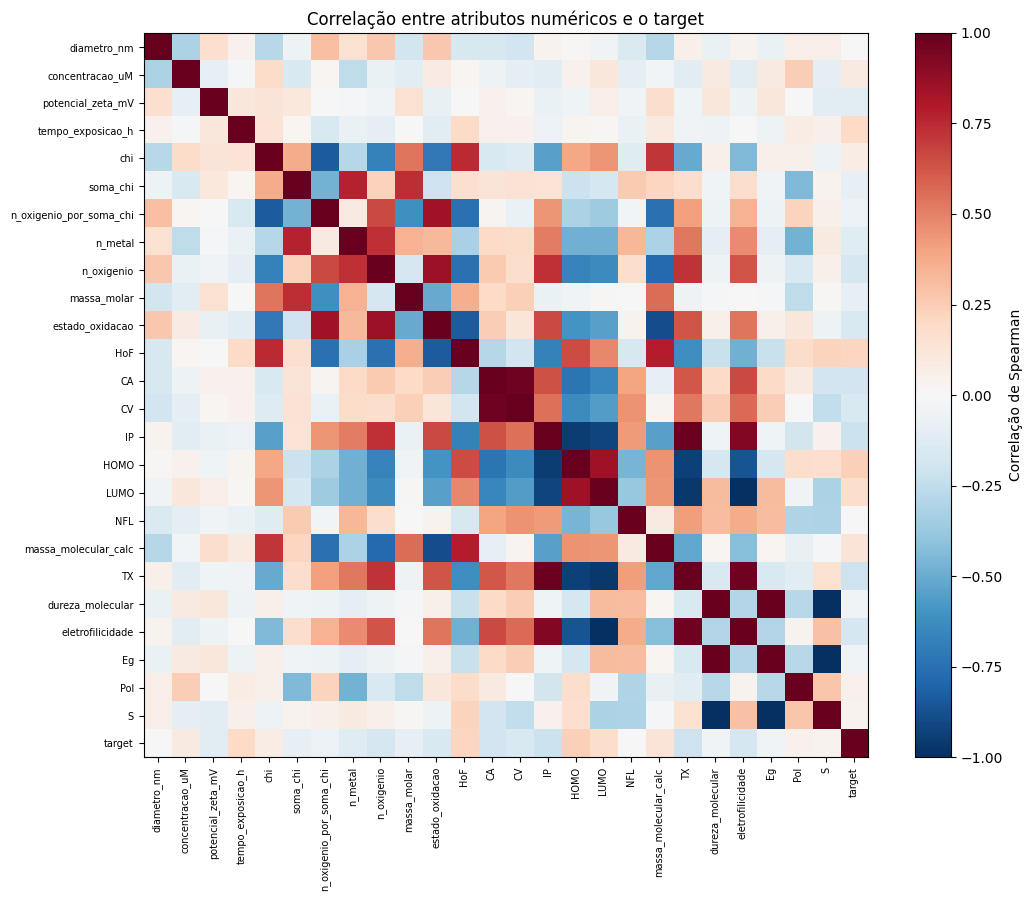

Pares com |rho| > 0.95 (candidatos à redundância): 9

Top 10 variáveis mais correlacionadas com o target:
HOMO                 0.241
IP                   0.217
HoF                  0.214
TX                   0.204
tempo_exposicao_h    0.199
CA                   0.193
eletrofilicidade     0.179
LUMO                 0.177
n_oxigenio           0.168
estado_oxidacao      0.150

Pares com |rho| > 0.95:
Eg                S                   1.000
dureza_molecular  S                   1.000
                  Eg                  1.000
LUMO              eletrofilicidade    0.997
IP                TX                  0.978
CA                CV                  0.975
TX                eletrofilicidade    0.971
LUMO              TX                  0.967
IP                HOMO                0.950


In [18]:

corr = dados_literatura[NUMERICAS + ["target"]].corr(
    method="spearman"
)

fig, ax = plt.subplots(figsize=(11, 9))

im = ax.imshow(
    corr,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(corr)))
ax.set_xticklabels(
    corr.columns,
    rotation=90,
    fontsize=7
)

ax.set_yticks(range(len(corr)))
ax.set_yticklabels(
    corr.columns,
    fontsize=7
)

fig.colorbar(
    im,
    ax=ax,
    label="Correlação de Spearman"
)

ax.set_title(
    "Correlação entre atributos numéricos e o target"
)

plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "matrix_correlacao_numericas")
plt.show()

# Pares altamente correlacionados

alta = (
    corr.abs()
        .where(
            np.triu(
                np.ones(corr.shape),
                1
            ).astype(bool)
        )
        .stack()
        .sort_values(ascending=False)
)

print(
    "Pares com |rho| > 0.95 (candidatos à redundância):",
    int((alta > 0.95).sum())
)

print("\nTop 10 variáveis mais correlacionadas com o target:")

print(
    corr["target"]
    .drop("target")
    .abs()
    .sort_values(ascending=False)
    .head(10)
    .round(3)
    .to_string()
)

print("\nPares com |rho| > 0.95:")

print(
    alta[alta > 0.95]
    .round(3)
    .to_string()
)

A análise de correlação identificou 9 pares com |rho| > 0.95, que se organizam em 3 grupos. O primeiro reúne 'Eg', 'dureza_molecular' e 'S', que possuem a mesma informação reescrita. O segundo agrupa descritores quânticos (HOMO, LUMO, IP, TX e eletrofilicidade). O terceiro é formado por CV e CA. Essa redundância é relevante, pois pode gerar pesos desproporcionais para modelos sensíveis à colinearidade. 

Em relação ao alvo, as correlações foram fracas. A maior foi a do HOMO, com 0.24. O que indica que nenhum atributo isolado explica a toxicidade.

### 4. Pré-processamento dos dados

#### 4.1 Removendo certos valores e modificando valores NaN:

In [19]:
dados_literatura.drop(columns=["viabilidade_pct", "id_linha"])

,nanoparticula,revestimento,diametro_nm,concentracao_uM,potencial_zeta_mV,linhagem_celular,celula_humana_animal,especie_celula,morfologia_celular,orgao_tecido,...,grupo_pontual,TX,dureza_molecular,eletrofilicidade,Eg,Pol,S,target,perfil_quantico,id_experimento
0,Ag,PEI,8.5,0.000049,-33.33,HepG2,H,Human,Epithelial,liver,...,1,1.5210,3.1760,0.364207,6.352,203.90417,0.314861,0,18,17
1,Ag,PEI,8.5,0.000098,-33.33,HepG2,H,Human,Epithelial,liver,...,1,1.5210,3.1760,0.364207,6.352,203.90417,0.314861,0,18,17
2,Ag,PEI,8.5,0.000246,-33.33,HepG2,H,Human,Epithelial,liver,...,1,1.5210,3.1760,0.364207,6.352,203.90417,0.314861,0,18,17
3,Ag,PEI,8.5,0.000492,-33.33,HepG2,H,Human,Epithelial,liver,...,1,1.5210,3.1760,0.364207,6.352,203.90417,0.314861,0,18,17
4,Ag,PEI,8.5,0.000738,-33.33,HepG2,H,Human,Epithelial,liver,...,1,1.5210,3.1760,0.364207,6.352,203.90417,0.314861,0,18,17
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2760,ZrO2,NaN,10.0,1623.073615,-45.50,HCT116,H,Human,Epithelial,Colon,...,9,1.6845,4.7265,0.300174,9.453,241.41374,0.211573,1,0,619
2761,ZrO2,NaN,10.0,405.768404,-45.50,A549,H,Human,Epithelial,Lung,...,9,1.6845,4.7265,0.300174,9.453,241.41374,0.211573,0,0,617
2762,ZrO2,NaN,10.0,811.536807,-45.50,A549,H,Human,Epithelial,Lung,...,9,1.6845,4.7265,0.300174,9.453,241.41374,0.211573,0,0,617
2763,ZrO2,NaN,10.0,1217.305211,-45.50,A549,H,Human,Epithelial,Lung,...,9,1.6845,4.7265,0.300174,9.453,241.41374,0.211573,1,0,617


A partir da análise exploratória dos dados, observou-se que a variável 'viabilidade_pct' não pode ser mantida no conjunto de atributos dos modelos, pois o 'target' de classificação foi definido diretamente a partir desse parâmetro. Sua inclusão resultaria em vazamento de dados, fornecendo ao modelo informações que já determinam o resultado a ser previsto e levando a estimativas artificialmente otimistas de desempenho. Dessa forma, essa variável foi removida da base de dados utilizada para treinamento e avaliação dos modelos. Além disso, a variável 'id_linha' também foi excluída  por se tratar apenas de um identificador das observações, sem significado experimental.

In [20]:
dados_literatura['revestimento'] = dados_literatura['revestimento'].fillna('nenhum')

Como os valores NaN só estão presentes na variável revestimento, e essa está em string, foi necessário trocar esses valores pela string 'nenhum' para padronizar essa variável.

In [21]:
colunas_remover = [
    "dureza_molecular",
    "S",
    "IP",
    "TX",
    "eletrofilicidade",
    "CV"
]

NOVASNUMERICAS = [c for c in NUMERICAS if c not in colunas_remover]

A partir da análise da correlação de Spearman, apresentada na Secção 3.7, verificou-se que algumas variáveis são fortemente correlacionados (|rho| > 0,95), a redundância foi tratada por seleção manual: em cada grupo de variáveis equivalentes, manteve-se um representante e removeram-se as demais. Optou-se pela seleção manual, em vez de usar o PCA como etapa do modelo, por manter a interpretabilidade dos atributos, já que cada componente seria uma combinação de várias propriedades do material. O PCA, por ser não supervisionado, também retém as direções de maior variância, e não necessariamente as mais informativas sobre a toxicidade.

#### 4.2 Função de codificação das variáveis categóricas

As variáveis categóricas, como 'revestimento' e 'ensaio', precisam ser convertidas para números antes de serem usadas pelos modelos. O dicionário 'CODIFICADORES' reúne três estratégias de codificação, e a função 'codificar_categorias' devolve uma instância nova do codificador escolhido. Assim, a codificação pode ser tratada como um hiperparâmetro e pode ser sorteada pelo Optuna.

In [22]:
CODIFICADORES = {
    "onehot":  lambda: OneHotEncoder(handle_unknown= "ignore"),
    "ordinal": lambda: OrdinalEncoder(handle_unknown= "use_encoded_value", unknown_value=-1),
    "target": lambda: TargetEncoder(target_type="binary", smooth=20,
                                cv=StratifiedKFold(5, shuffle=True, random_state=SEMENTE_ALEATORIA))}
    

def codificar_categoricas(codificador):
    return CODIFICADORES[codificador]()


Os codificadores usados foram: OneHotEnconder, que cria uma coluna binária para cada categoria e não impõe ordem entre categorias; OrdinalEnconder, que atribui um número inteiro para cada categoria, no entanto, acaba criando uma ordem entre categorias nominais; e TargetEnconder, que substitui cada categoria pela taxa média de toxicidade observada nela.

#### 4.3 Função de normalização

Os atributos numéricos tem escalas muito diferentes, como descrito na Secção 3.2. O dicionário 'NORMALIZADORES' reúne as cinco opções avaliadas, e a função 'normalizar' devolve uma instância nova do normalizador escolhido. Assim, como a codificação, a normalização é tratada como hiperparâmetro pelo Optuna.

A 'concentracao_uM' abrange cerca de 24 ordens de grandeza, como foi constatado na Secção 3.2. Por isso, aplicou-se a transformação logarítmica antes da normalização. Valores abaixo da grandeza de $10^-12$ foram truncados nesse limite antes do log, por serem fisicamente incoerentes.

In [23]:
NORMALIZADORES = {
    "nenhum":   lambda: "passthrough",
    "standard": lambda: StandardScaler(),
    "minmax":   lambda: MinMaxScaler(),
    "maxabs":   lambda: MaxAbsScaler(),
    "robust":   lambda: RobustScaler()
}


def log10_conc(x):
    """ log10 da concentração (microM)"""
    return np.log10(np.clip(x,1e-12,None))

def normalizar(normalizador):
    return NORMALIZADORES[normalizador]()

def normalizar_conc(normalizador):
    return Pipeline([("log", FunctionTransformer(log10_conc, feature_names_out= "one-to-one")),
                     ("normalizador", NORMALIZADORES[normalizador]()),
                     ])

Os normalizadores usados foram: StandardScaler, que subtrai a média e divide pelo desvio padrão; MinMaxScaler, que reescala cada variável para um intervalo entre 0 e 1; MaxAbsScaler, que divide pelo maior valor absoluto, o que leva os dados para [-1,1]; e RobustScaler, que utiliza a mediana e o intervalo interquartil. O argumento 'nenhum' mantém os valores originais.

#### 4.4 Montando uma função de pré-processamento com redução de dimensionalidade.

A função preprocessamento monta o ColumnTransformer que prepara os atributos antes de qualquer modelo. Como essa função é encadeada com um Pipeline, o pré-processamento é ajustado apenas com dados de treino de cada fold da validação cruzada.

In [24]:
def preprocessamento(encoder, scaler, categoricas = CATEGORICAS, numericas= NOVASNUMERICAS):
    sem_conc = [c for c in numericas if c != "concentracao_uM"]
    return ColumnTransformer([
        ("concentração", normalizar_conc(scaler), ["concentracao_uM"]),
        ("numericas", normalizar(scaler), sem_conc),
        ("categóricas", codificar_categoricas(encoder), categoricas)
    ])

#### 4.5 Função geral para as métricas

In [25]:
def calcular_metricas(y_true, proba, pred):
    return {
        "PR-AUC":   average_precision_score(y_true, proba),
        "ROC-AUC":  roc_auc_score(y_true, proba),
        "MCC":      matthews_corrcoef(y_true, pred),
        "F1":       f1_score(y_true, pred, zero_division=0),
        "Recall":   recall_score(y_true, pred, zero_division=0),
        "Precisão": precision_score(y_true, pred, zero_division=0),
        "Acurácia": accuracy_score(y_true, pred),
    }

### 5. Divisão entre treino e teste

A partir da secção 3.6, foi possível observar que, essencialmente, só existem 621 experimentos distintos. Dessa forma, a separação de treino e teste não foi feita de forma aleatória, pois grupos do mesmo experimento cairiam no mesmo grupo, e, consequentemente, ocorreria vazamento de dados.

In [26]:
SEMENTE_ALEATORIA = 60

divisao = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMENTE_ALEATORIA)
indices_treino, indices_teste = next(divisao.split(dados_literatura[ATRIBUTOS], dados_literatura['target'], groups=dados_literatura["id_experimento"]))

dados_literatura_treino, dados_literatura_teste = dados_literatura.iloc[indices_treino], dados_literatura.iloc[indices_teste]

X_treino, Y_treino = dados_literatura_treino[ATRIBUTOS], dados_literatura_treino['target']
X_teste, Y_teste = dados_literatura_teste[ATRIBUTOS], dados_literatura_teste['target']
g_treino = dados_literatura_treino[["id_experimento", "nanoparticula"]]
g_teste = dados_literatura_teste[["id_experimento", "nanoparticula"]]

In [27]:
print(len(dados_literatura_treino), len(dados_literatura_teste)) # tamanhos
print(Y_treino.mean(), Y_teste.mean())                           # proporção de tóxicos
print(len(set(g_treino["nanoparticula"]) & set(g_teste["nanoparticula"])), "materiais nos dois lados")

2209 556
0.23675871435038479 0.2392086330935252
17 materiais nos dois lados


O treino ficou com 2.209 medidas e o teste com 556, aproximadamente uma razão de 1:4. 

Como foi definido, o agrupamento foi realizado por experimento, e não por nanopartícula, o mesmo material pode aparecer no treino e no teste, em experimentos diferentes. Portanto, o desempenho no teste mede a capacidade de prever novos experimentos de materiais já conhecidos, e não prever a toxicidade de nanopartículas inéditas.

### 6. Modelo Baseline 

O modelo baseline foi implementado utilizando um DummyClassifier com entratégia de predição da classe majoritária. Esse modelo não utiliza as variáveis explicativas do conjunto de dados, e serve apenas como referência mínima de desempenho.

In [28]:
baseline = DummyClassifier(strategy="prior")
baseline.fit(X_treino, Y_treino)

proba_baseline = baseline.predict_proba(X_teste)[:, 1]    # constante = proporção de tóxicos no treino
y_pred_baseline = baseline.predict(X_teste)      # sempre a classe majoritária


metricas_baseline = calcular_metricas(Y_teste, proba_baseline, y_pred_baseline)
print(metricas_baseline)

{'PR-AUC': 0.2392086330935252, 'ROC-AUC': 0.5, 'MCC': 0.0, 'F1': 0.0, 'Recall': 0.0, 'Precisão': 0.0, 'Acurácia': 0.7607913669064749}


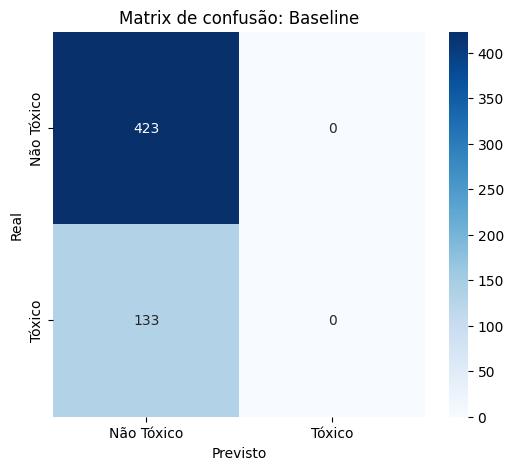

In [29]:
y_verdadeiro = Y_teste
y_previsao = baseline.predict(X_teste)

cm_baseline = confusion_matrix(Y_teste, y_pred_baseline)

plt.figure(figsize=(6, 5))

sns.heatmap(cm_baseline, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Não Tóxico', 'Tóxico'],
            yticklabels=['Não Tóxico', 'Tóxico'])
plt.title('Matrix de confusão: Baseline')
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.savefig(PASTA_FIGURAS / "matriz_confusao_baseline.png")
plt.show()



No conjunto de teste, ele atingiu a acurácia de 0.761, valor que reflete a proporção de medidas não tóxicas. A métrica PR-AUC, que avalia a ordenação das probabilidades, coincide com a proporção de tóxicos, ou seja, 0.239. Já a métrica MCC, que avalia as decisões tomadas com um limiar fixo, é dado por 0.0. Por isso, o desempenho dos modelos foi avaliado principalmente por PR-AUC e MCC, e não por acurácia.

### 7. Modelos e Otimização de Hiperpâmetros

#### 7.1 Modelo KNeighbors Classifier

O algoritimo dos k vizinhos mais próximos classifica uma medida a partir das medidas mais parecidas do conjunto de treino. O código foi organizado em três funções, que permitem ao Optuna buscar, os hiperparâmetros do modelo e as escolhas de pré-processamento. 

A função 'cria_instancia_knn' recebe um trial do Optuna e devolve um KNeighborsClassifier com os hiperparâmetros sorteados. A função 'montar_knn' monta o Pipeline completo, que associa o pré-processamento ao modelo. Por fim, a função 'funcao_knn_nanotox' monta um modelo com hiperparâmetros sorteados a cada trial e o avalia por validação cruzada em 5 partes através do StratifiedGroupKFold.

O espaço de busca do KNN contém três hiperparâmetros. O número de vizinhos varia de 3 a 440, em escala logarítimica. O seu limite superior está no máximo do tamanho de treino de cada fold.A escala logarítimica dá mais resolução aos valores pequenos, onde o desempenho varia mais. Os pesos dos vizinhos podem ser uniformes ('uniform') ou inversamente proporcionais à distância('distance'), ou seja, vizinhos mais próximos contam mais. A métrica da distância pode ser a de Manhattan (p = 1)  ou a euclidiana (p = 2).


In [30]:
def cria_instancia_knn(trial):
    """Cria uma instância de um KNeighborsClassifier.

    Args:
    trial: objeto tipo Trial do optuna.

    Returns:
    Uma instância do KNeighborsClassifier
    """
    parametros = {
      "n_neighbors": trial.suggest_int("num_vizinhos", 1, 440, log=True),
      "weights": trial.suggest_categorical("pesos", ["uniform","distance"]),
      "p": trial.suggest_int("p_minkowski", 1, 2),

      "n_jobs": -1,
     }
    
    return KNeighborsClassifier(**parametros)

def montar_knn(trial):
    norm = trial.suggest_categorical("normalizador", ["nenhum", "standard", "minmax", "maxabs","robust"])
    cod = trial.suggest_categorical("codificador", ["onehot", "target"])

    return Pipeline([
        ("preprocessamento", preprocessamento(cod, norm)),
        ("knn", cria_instancia_knn(trial))
    ])

def funcao_knn_nanotox(trial, X, y, grupos, num_folds=5):
    modelo = montar_knn(trial)
    cv = StratifiedGroupKFold(n_splits=num_folds, shuffle=True, random_state=SEMENTE_ALEATORIA)
    metricas = cross_val_score(modelo, X, y, groups=grupos, cv=cv,
                             scoring="average_precision", error_score="raise")

    return  np.nanmean(metricas)

O estudo do Optuna é salvo em 'knn_nanotoxicidade', o que permite retomar a busca e consultar tentativas depois. 

In [31]:
NOME_DO_ESTUDO = "knn_nanotoxicidade"

knn_nanotox = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=optuna.samplers.TPESampler(seed=SEMENTE_ALEATORIA)
)

A busca foi executada sobre o conjunto de treino, com a função 'funcao_knn_nanotox_parcial', que fixa os dados e deixa apenas trial como argumento. Em cada tentativa, o Optuna sorteia uma combinação de hiperparâmetros e de pré-processamento, monta o modelo e o avalia por validação cruzada em 5 partes. 

Foram realizadas 100 tentativas completas. A melhor combinação encontrada foi {'normalizador': 'maxabs', 'codificador': 'target', 'num_vizinhos': 12, 'pesos': 'distance', 'p_minkowski': 1}, com PR-AUC de, aproximadamente, 0.68. 

In [32]:
NUM_FOLDS = 5

def funcao_knn_nanotox_parcial(trial):
    return funcao_knn_nanotox(trial, X_treino, Y_treino, g_treino["id_experimento"], num_folds=NUM_FOLDS)

NUM_TENTATIVAS = 100


knn_nanotox.optimize(funcao_knn_nanotox_parcial, n_trials=NUM_TENTATIVAS)

print(knn_nanotox.best_params)
print(knn_nanotox.best_value)

{'normalizador': 'maxabs', 'codificador': 'target', 'num_vizinhos': 12, 'pesos': 'distance', 'p_minkowski': 1}
0.6817007128968168


Para analisar como o número de vizinhos influencia o desempenho do modelo, esse número foi variado entre 3 e 201,e os demais hiperparâmetros foram fixados na melhor configuração encontrada.

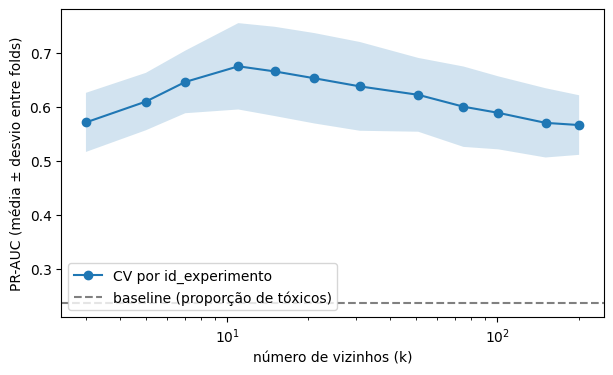

In [33]:
from optuna.trial import FixedTrial


vizinhos = [3, 5, 7, 11, 15, 21, 31, 51, 75, 101, 151, 201]
resultados = []

for col in ["id_experimento"]:
    for k in vizinhos:
        params = {**knn_nanotox.best_params, "num_vizinhos": k}
        modelo = montar_knn(FixedTrial(params))          
        cv = StratifiedGroupKFold(5, shuffle=True, random_state=SEMENTE_ALEATORIA)
        scores = cross_val_score(modelo, X_treino, Y_treino, groups=g_treino[col],
                                 cv=cv, scoring="average_precision")
        resultados.append({"grupo": col, "k": k, "media": scores.mean(), "desvio": scores.std()})

df_k = pd.DataFrame(resultados)

fig, ax = plt.subplots(figsize=(7, 4))
for col, d in df_k.groupby("grupo"):
    ax.plot(d["k"], d["media"], marker="o", label=f"CV por {col}")
    ax.fill_between(d["k"], d["media"] - d["desvio"], d["media"] + d["desvio"], alpha=0.2)
ax.axhline(Y_treino.mean(), color="gray", linestyle="--", label="baseline (proporção de tóxicos)")
ax.set_xscale("log")
ax.set_xlabel("número de vizinhos (k)")
ax.set_ylabel("PR-AUC (média ± desvio entre folds)")
ax.legend()
plt.show()

Após a conclusão da busca por hiperparâmetros, a melhor configuração do KNN foi treinada como todo o conjunto de treino. Em seguida, o modelo foi aplicado uma única vez ao conjunto de teste. O KNN obteve PR-AUC de 0.68 e MCC de 0.437 no conjunto de teste, contra 0.239 e 0.0 do baseline.

In [34]:

# 1. Monta o melhor modelo e treina com o treino
melhor_knn = montar_knn(FixedTrial(knn_nanotox.best_params))   
melhor_knn.fit(X_treino, Y_treino)

# 2. Prediz no teste
proba_knn = melhor_knn.predict_proba(X_teste)[:, 1]
y_pred_knn = (proba_knn >= 0.5).astype(int)

# 3. Métricas

metricas_knn = calcular_metricas(Y_teste, proba_knn, y_pred_knn)
print(metricas_knn)


{'PR-AUC': 0.6798331511725698, 'ROC-AUC': 0.8335199701381113, 'MCC': 0.43768578269745867, 'F1': 0.5454545454545454, 'Recall': 0.47368421052631576, 'Precisão': 0.6428571428571429, 'Acurácia': 0.8111510791366906}


Para entender quais escolhas mais influenciaram o desempenho do KNN, foi calculado a importância de cada hiperparâmetro. No entanto, esse resultado deve ser lido com cautela, já que uma importância baixa não significa que o hiperparâmetro seja irrelevante, e sim que, no espaço explorado, variá-lo modou pouco o PR-AUC em comparação com o número de vizinhos.

In [35]:
vis.plot_param_importances(knn_nanotox)

#### 7.2 Modelo Logistic Regression

O algoritimo Regressão Logística prevê a probabilidade de uma medida ter o rótulo 1. O código foi organizado em três funções, que permitem ao Optuna buscar, os hiperparâmetros do modelo e as escolhas de pré-processamento. 

A função 'cria_instancia_logreg' recebe um trial do Optuna e devolve um LogisticRegression com os hiperparâmetros sorteados. A função 'montar_logreg' monta o Pipeline completo, que associa o pré-processamento ao modelo. Por fim, a função 'funcao_logreg_nanotox' monta um modelo com hiperparâmetros sorteados a cada trial e o avalia por validação cruzada em 5 partes através do StratifiedGroupKFold.

O espaço de busca da regressão logística contém dois hiperparâmetros. O parâmetro 'C' varia de $10^{-4}$ a $10$, em escala logarítimica, já que o seu efeito é multiplicativo, ou seja, o limite inferior corresponde a um modelo quase em poder preditivo, e o superior evita a regularização fraca. O peso das classes pode ser uniforme('None') ou balanceado, no qual é inversamente proporcional à frequência de cada classe. Os demais parâmetros foram fixados, solver como 'lbfgs' e até 5000 iterações, para evitar o 'ConvergenceWarning'.

In [36]:
def cria_instancia_logreg(trial):
    """Cria uma instância de um LogisticRegression.

    Args:
    trial: objeto tipo Trial do optuna.

    Returns:
    Uma instância do LogisticRegression
    """
    parametros = {
      "C": trial.suggest_float("C", 1e-4, 1e1, log=True),
      "class_weight": trial.suggest_categorical("class_weight", [None,"balanced"]),
      "solver": "lbfgs",
      "max_iter": 5000,
    
     }
    
    return LogisticRegression(**parametros)



def montar_logreg(trial):
    norm = trial.suggest_categorical("normalizador", ["nenhum", "standard", "minmax", "maxabs","robust"])
    cod = trial.suggest_categorical("codificador", ["onehot", "target"])

    return Pipeline([
        ("preprocessamento", preprocessamento(cod, norm)),
        ("reglog", cria_instancia_logreg(trial))
    ])



def funcao_logreg_nanotox(trial, X, y, grupos, num_folds=5):
    modelo = montar_logreg(trial)
    cv = StratifiedGroupKFold(n_splits=num_folds, shuffle=True, random_state=SEMENTE_ALEATORIA)
    metricas = cross_val_score(modelo, X, y, groups=grupos, cv=cv,
                               scoring="average_precision", error_score= "raise")

    return np.nanmean(metricas)

O estudo do Optuna é salvo em 'logreg_nanotoxicidade', o que permite retomar a busca e consultar tentativas depois. 

In [37]:
NOME_DO_ESTUDO = "logreg_nanotoxicidade"

logreg_nanotox = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=optuna.samplers.TPESampler(seed=SEMENTE_ALEATORIA)
)

A busca foi executada sobre o conjunto de treino, com a função 'funcao_objetivo_parcial_logreg', que fixa os dados e deixa apenas trial como argumento. Em cada tentativa, o Optuna sorteia uma combinação de hiperparâmetros e de pré-processamento, monta o modelo e o avalia por validação cruzada em 5 partes. 

Foram realizadas 100 tentativas completas. A melhor combinação encontrada foi {'normalizador': 'standard', 'codificador': 'onehot', 'C': 0.8018087465011806, 'class_weight': None}, com PR-AUC de, aproximadamente, 0.597. 

In [38]:
NUM_FOLDS = 5

def funcao_logreg_nanotox_parcial(trial):
    return funcao_logreg_nanotox(trial, X_treino, Y_treino, g_treino["id_experimento"], num_folds=NUM_FOLDS)

NUM_TENTATIVAS = 100


logreg_nanotox.optimize(funcao_logreg_nanotox_parcial, n_trials=NUM_TENTATIVAS)

print(logreg_nanotox.best_params)
print(logreg_nanotox.best_value)

{'normalizador': 'standard', 'codificador': 'onehot', 'C': 0.8018087465011806, 'class_weight': None}
0.596671152320547


Após a conclusão da busca por hiperparâmetros, a melhor configuração do Logistic Regression foi treinada como todo o conjunto de treino. Em seguida, o modelo foi aplicado uma única vez ao conjunto de teste. O algoritmo obteve PR-AUC de 0.651 e MCC de 0.446 no conjunto de teste, contra 0.239 e 0.0 do baseline.

In [39]:
melhor_logreg = montar_logreg(FixedTrial(logreg_nanotox.best_params))   
melhor_logreg.fit(X_treino, Y_treino)

# 2. Prediz no teste
proba_logreg = melhor_logreg.predict_proba(X_teste)[:, 1]
y_pred_logreg = (proba_logreg >= 0.5).astype(int)


# 3. Métricas

metricas_logreg = calcular_metricas(Y_teste, proba_logreg, y_pred_logreg)
print(metricas_logreg)

{'PR-AUC': 0.6510845300397023, 'ROC-AUC': 0.8169892817149257, 'MCC': 0.44659578871409883, 'F1': 0.5502183406113537, 'Recall': 0.47368421052631576, 'Precisão': 0.65625, 'Acurácia': 0.814748201438849}


Para entender quais escolhas mais influenciaram o desempenho do Logistic Regression, foi calculado a importância de cada hiperparâmetro. No entanto, esse resultado deve ser lido com cautela, já que uma importância baixa não significa que o hiperparâmetro seja irrelevante, e sim que, no espaço explorado, variá-lo modou pouco o PR-AUC em comparação ao 'C'.

In [40]:
vis.plot_param_importances(logreg_nanotox)

#### 7.3  Modelo Decision Tree Classifier

O algoritimo Decision Tree Classifier escolhe o condicional que resulta em uma maior redução da impureza dos vértices filhos. O código foi organizado em três funções, que permitem ao Optuna buscar, os hiperparâmetros do modelo e as escolhas de pré-processamento. 

A função 'cria_instancia_dtree' recebe um trial do Optuna e devolve um DecisionTreeClassifier com os hiperparâmetros sorteados. A função 'montar_dtree' monta o Pipeline completo, que associa o pré-processamento ao modelo, que, nesse caso, não necessita de normalização. Por fim, a função 'funcao_dtree_nanotox' monta um modelo com hiperparâmetros sorteados a cada trial e o avalia por validação cruzada em 5 partes através do StratifiedGroupKFold.

O espaço de busca da árvore de decisão contém cinco hiperparâmetros. O 'criterion' está relacionado com a impureza, podendo ser 'gini', que indica a probabilidade de classificar errado um exemplo sorteado ao acaso no nó, ou 'entropy', que penaliza um pouco mais nós misturados (entropia de Shannon). Já o 'class_weight' controla o peso das classes e pode ser uniforme ou balanceado, e por isso, altera o cálculo da impureza e modifica a estrutura da árvove. Os outros três parâmetros controlam a complexidade. O 'max_depth' controla a profundidade máxima, e varia de 2 a 20. O 'min_samples_split' corresponde ao número mínimo de exemplos para dividir um nó e pode variar de 2 a 50. Já o 'min_samples_leaf' representa o número minimo de exemplos por folha, e pode estar entre 1 a 30. Os limites inferiores correspondem à árvore menos restrita possível, e os superiores a uma com regularização forte. O 'random_state' foi fixado para manter as execuções reprodutíveis.


In [41]:
def cria_instancia_dtree(trial):
    """Cria uma instância de um Decision Tree Classifier.

    Args:
    trial: objeto tipo Trial do optuna.

    Returns:
    Uma instância do Decision Tree Classifier
    """
    parametros = {
      "criterion": trial.suggest_categorical("criterio", ["gini",  "entropy"]),
      "class_weight": trial.suggest_categorical("class_weight", [None,"balanced"]),
      "max_depth": trial.suggest_int("profundidade_max", 2, 20),
      "min_samples_split": trial.suggest_int("min_exemplos_split", 2, 50),
      "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 1, 30),
      "random_state": SEMENTE_ALEATORIA
    
     }
    
    return DecisionTreeClassifier(**parametros)


def montar_dtree(trial):
    cod = trial.suggest_categorical("codificador", ["onehot", "ordinal","target"])
    return Pipeline([
        ("preprocessamento", preprocessamento(cod, "nenhum")), 
        ("dtree", cria_instancia_dtree(trial))
    ])

def funcao_dtree_nanotox(trial, X, y, grupos, num_folds=5):
    modelo = montar_dtree(trial)
    cv = StratifiedGroupKFold(n_splits=num_folds, shuffle=True, random_state=SEMENTE_ALEATORIA)
    metricas = cross_val_score(modelo, X, y, groups=grupos, cv=cv,
                               scoring="average_precision", error_score= "raise")

    return np.nanmean(metricas)

O estudo do Optuna é salvo em 'dtree_nanotoxicidade', o que permite retomar a busca e consultar tentativas depois. 

In [42]:
NOME_DO_ESTUDO = "dtree_nanotoxicidade"

dtree_nanotox = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=optuna.samplers.TPESampler(seed=SEMENTE_ALEATORIA)
)

A busca foi executada sobre o conjunto de treino, com a função 'funcao_dtree_nanotox_parcial', que fixa os dados e deixa apenas trial como argumento. Em cada tentativa, o Optuna sorteia uma combinação de hiperparâmetros e de pré-processamento, monta o modelo e o avalia por validação cruzada em 5 partes. 

Foram realizadas 100 tentativas completas. A melhor combinação encontrada foi
{'codificador': 'onehot', 'criterio': 'entropy', 'class_weight': 'balanced', 'profundidade_max': 15, 'min_exemplos_split': 36, 'min_exemplos_folha': 13}, com PR-AUC de, aproximadamente, 0.61 

In [43]:
NUM_FOLDS = 5

def funcao_parcial_dtree_nanotox(trial):
    return funcao_dtree_nanotox(trial, X_treino, Y_treino, g_treino["id_experimento"], num_folds=NUM_FOLDS)

NUM_TENTATIVAS = 100




dtree_nanotox.optimize(funcao_parcial_dtree_nanotox, n_trials=NUM_TENTATIVAS)

print(dtree_nanotox.best_params)
print(dtree_nanotox.best_value)

{'codificador': 'onehot', 'criterio': 'entropy', 'class_weight': 'balanced', 'profundidade_max': 15, 'min_exemplos_split': 36, 'min_exemplos_folha': 13}
0.6105201104519506


Após a conclusão da busca por hiperparâmetros, a melhor configuração do Decision Tree Classifier foi treinada como todo o conjunto de treino. Em seguida, o modelo foi aplicado uma única vez ao conjunto de teste. Esse algoritmo obteve PR-AUC de 0.711 e MCC de 0.520 no conjunto de teste, contra 0.239 e 0.0 do baseline.

In [44]:
melhor_dtree = montar_dtree(FixedTrial(dtree_nanotox.best_params))   
melhor_dtree.fit(X_treino, Y_treino)


proba_dtree = melhor_dtree.predict_proba(X_teste)[:, 1]
y_pred_dtree = (proba_dtree >= 0.5).astype(int)

# Métricas
metricas_dtree = calcular_metricas(Y_teste, proba_dtree, y_pred_dtree)
print(metricas_dtree)

{'PR-AUC': 0.7113768613201663, 'ROC-AUC': 0.8814500790984553, 'MCC': 0.5204643794812157, 'F1': 0.6439628482972136, 'Recall': 0.7819548872180451, 'Precisão': 0.5473684210526316, 'Acurácia': 0.7931654676258992}


Para entender quais escolhas mais influenciaram o desempenho da Decision Tree Classifier, foi calculado a importância de cada hiperparâmetro. No entanto, esse resultado deve ser lido com cautela, já que uma importância baixa não significa que o hiperparâmetro seja irrelevante, e sim que, no espaço explorado, variá-lo modou pouco o PR-AUC em comparação ao 'min_exemplos_folha'.

In [45]:
vis.plot_param_importances(dtree_nanotox)

#### 7.4 Modelo Random Florest Classifier

O algoritimo Random Florest Classifier que reúne várias árvores, onde cada árvore faz a sua previsão individual e a moda delas é a previsão final. O código foi organizado em três funções, que permitem ao Optuna buscar, os hiperparâmetros do modelo e as escolhas de pré-processamento. 

A função 'cria_instancia_rflorest' recebe um trial do Optuna e devolve um RandomFlorestClassifier com os hiperparâmetros sorteados. A função 'montar_rflorest' monta o Pipeline completo, que associa o pré-processamento ao modelo, que, nesse caso, não necessita de normalização. Por fim, a função 'funcao_rflorest_nanotox' monta um modelo com hiperparâmetros sorteados a cada trial e o avalia por validação cruzada em 5 partes através do StratifiedGroupKFold.

O espaço da busca da floresta aleatória contém sete hiperparâmetros. O 'n_estimators' controla o número de árvores que varia de 50 a 500 (escala logarítmica), o seu limite inferior evita instabilidade, e o superior seria a região que o desempenho já satura. O 'criterion' está relacionado com a impureza, podendo ser 'gini', que indica a probabilidade de classificar errado um exemplo sorteado ao acaso no nó, ou 'entropy', que penaliza um pouco mais nós misturados (entropia de Shannon). Já o 'class_weight' controla o peso das classes e pode ser uniforme ou balanceado, e por isso, altera o cálculo da impureza e modifica a estrutura da árvove. Os outros três parâmetros controlam a complexidade. O 'max_depth' controla a profundidade máxima, e varia de 2 a 20. O 'min_samples_split' corresponde ao número mínimo de exemplos para dividir um nó e pode variar de 2 a 50. Já o 'min_samples_leaf' representa o número minimo de exemplos por folha, e pode estar entre 1 a 30. Os limites inferiores correspondem à árvore menos restrita possível, e os superiores a uma com regularização forte. Por fim, o 'max_features' corresponde a fração de variáveis consideradas em cada divisão (0,1 a 1,0) controla a correlação entre as árvores. O uso de 'bootstrap' foi mantido fixo, por ser a característica que define o método, e a semente aleatória foi fixada para tornar o resultado reprodutível.

In [46]:
def cria_instancia_rflorest(trial):
    """Cria uma instância de um Random Florest Classifier.

    Args:
    trial: objeto tipo Trial do optuna.

    Returns:
    Uma instância do Random Florest Classifier
    """
    parametros = {
      "n_estimators": trial.suggest_int("num_arvores", 50, 500, log=True),
      "criterion": trial.suggest_categorical("criterio", ["gini",  "entropy"]),
      "class_weight": trial.suggest_categorical("class_weight", [None,"balanced_subsample"]),
      "max_depth": trial.suggest_int("profundidade_max", 3, 30),
      "min_samples_split": trial.suggest_int("min_exemplos_split", 2, 30),
      "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 1, 20),
      "max_features": trial.suggest_float("frac_max_atributos", 0.1, 1.0),
      "bootstrap": True,
      "n_jobs": -1,
      "random_state": SEMENTE_ALEATORIA
    
     }
    
    return RandomForestClassifier(**parametros)


def montar_rflorest(trial):
    cod = trial.suggest_categorical("codificador", ["onehot", "ordinal","target"])
    return Pipeline([
        ("preprocessamento", preprocessamento(cod, "nenhum")),
        ("dtree", cria_instancia_rflorest(trial))
    ])

def funcao_rflorest_nanotox(trial, X, y, grupos, num_folds=5):
    modelo = montar_rflorest(trial)
    cv = StratifiedGroupKFold(n_splits=num_folds, shuffle=True, random_state=SEMENTE_ALEATORIA)
    metricas = cross_val_score(modelo, X, y, groups=grupos, cv=cv,
                               scoring="average_precision", error_score= "raise")

    return np.nanmean(metricas)

O estudo do Optuna é salvo em 'rflorest_nanotoxicidade', o que permite retomar a busca e consultar tentativas depois. 

In [47]:

NOME_DO_ESTUDO = "rflorest_nanotoxicidade"

rflorest_nanotox = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=optuna.samplers.TPESampler(seed=SEMENTE_ALEATORIA)
)

A busca foi executada sobre o conjunto de treino, com a função 'funcao_rflorest_nanotox_parcial', que fixa os dados e deixa apenas trial como argumento. Em cada tentativa, o Optuna sorteia uma combinação de hiperparâmetros e de pré-processamento, monta o modelo e o avalia por validação cruzada em 5 partes. 

Foram realizadas 100 tentativas completas. A melhor combinação encontrada foi
{'codificador': 'ordinal', 'num_arvores': 405, 'criterio': 'entropy', 'class_weight': None, 'profundidade_max': 27, 'min_exemplos_split': 2, 'min_exemplos_folha': 1, 'frac_max_atributos': 0.37387135899086643}, com PR-AUC de, aproximadamente, 0.78. 

In [48]:
NUM_FOLDS = 5

def funcao_rflorest_nanotox_parcial(trial):
    return funcao_rflorest_nanotox(trial, X_treino, Y_treino, g_treino["id_experimento"], num_folds=NUM_FOLDS)

NUM_TENTATIVAS = 100


rflorest_nanotox.optimize(funcao_rflorest_nanotox_parcial, n_trials=NUM_TENTATIVAS)

print(rflorest_nanotox.best_params)
print(rflorest_nanotox.best_value)

{'codificador': 'ordinal', 'num_arvores': 405, 'criterio': 'entropy', 'class_weight': None, 'profundidade_max': 27, 'min_exemplos_split': 2, 'min_exemplos_folha': 1, 'frac_max_atributos': 0.37387135899086643}
0.782060149553535


Após a conclusão da busca por hiperparâmetros, a melhor configuração do Random Florest Classifier foi treinada como todo o conjunto de treino. Em seguida, o modelo foi aplicado uma única vez ao conjunto de teste. Esse algoritmo obteve PR-AUC de 0.836 e MCC de 0.626 no conjunto de teste.

In [49]:
melhor_rflorest = montar_rflorest(FixedTrial(rflorest_nanotox.best_params))   
melhor_rflorest.fit(X_treino, Y_treino)


proba_rflorest = melhor_rflorest.predict_proba(X_teste)[:, 1]
y_pred_rflorest = (proba_rflorest >= 0.5).astype(int)

# Métricas
metricas_rflorest = calcular_metricas(Y_teste, proba_rflorest, y_pred_rflorest)
print(metricas_rflorest)

{'PR-AUC': 0.8364802419047146, 'ROC-AUC': 0.9343127321850726, 'MCC': 0.6257785132491651, 'F1': 0.7024793388429752, 'Recall': 0.6390977443609023, 'Precisão': 0.7798165137614679, 'Acurácia': 0.8705035971223022}


Para entender quais escolhas mais influenciaram o desempenho do Random Florest Classifier, foi calculado a importância de cada hiperparâmetro. No entanto, esse resultado deve ser lido com cautela, já que uma importância baixa não significa que o hiperparâmetro seja irrelevante, e sim que, no espaço explorado, variá-lo modou pouco o PR-AUC em comparação ao 'min_exemplos_folha'.

In [50]:
vis.plot_param_importances(rflorest_nanotox)

#### 7.5 Modelo Gradient Boosting

No algoritmo Gradient Boosting,as árvores são construídas em sequência, desse modo, cada uma corrige os erros do conjunto anterior, com contribuição pela taxa de aprendizado, assim, produz previsões precisas ao combinar múltiplos modelos de precisão fracos. O código foi organizado em três funções, que permitem ao Optuna buscar, os hiperparâmetros do modelo e as escolhas de pré-processamento. 

A função 'cria_instancia_boosting' recebe um trial do Optuna e devolve um GradientBoostingClassifier com os hiperparâmetros sorteados. A função 'montar_boosting' monta o Pipeline completo, que associa o pré-processamento ao modelo, que, nesse caso, não necessita de normalização. Por fim, a função 'funcao_boosting_nanotox' monta um modelo com hiperparâmetros sorteados a cada trial e o avalia por validação cruzada em 5 partes através do StratifiedGroupKFold.

O espaço de busca do gradient boosting contém seis hiperparâmetros. O 'n_estimators' corresponde ao número de árvores e varia de 50 a 500 e o 'learning_rate', ou seja, a taxa de aprendizado de $10^{-5}$ a $0.5$, ambos em escala logarítmica. O 'max_depth' representa a profundidade máxima que varia entre 1 a 6, por serem usadas árvores rasas, o 'max_samples_leaf', número mínimo de exemplos por folha, varia de 1 a 30. Dois parâmetros adicionam aleatoriedade e regularização, o 'sub_sample' e o 'max_features' que representam, respectivamente, a fração de trieno usada em cada árvore e a fração de variáveis consideráveis em cada divisão. Por fim, a semente aleatória foi fixada para garantir que o resultado seja reprodutível.

In [51]:
def cria_instancia_boosting(trial):

    parametros = {
        "n_estimators": trial.suggest_int("num_arvores", 50, 500, log=True),
        "learning_rate": trial.suggest_float("taxa_aprendizado", 1e-3, 0.5, log=True),
        "max_depth": trial.suggest_int("profundidade_max", 1, 6),
        "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 1, 30),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "max_features": trial.suggest_float("frac_max_atributos", 0.2, 1.0),
        "random_state": SEMENTE_ALEATORIA,
    }
    return GradientBoostingClassifier(**parametros)


def montar_boosting(trial):
    cod = trial.suggest_categorical("codificador", ["onehot", "ordinal", "target"])
    return Pipeline([
        ("preprocessamento", preprocessamento(cod, "nenhum")),  
        ("boosting", cria_instancia_boosting(trial)),
    ])


def funcao_boosting_nanotox(trial, X, y, grupos, num_folds=5):
    modelo = montar_boosting(trial)
    cv = StratifiedGroupKFold(n_splits=num_folds, shuffle=True, random_state=SEMENTE_ALEATORIA)
    scores = cross_val_score(modelo, X, y, groups=grupos, cv=cv,
                             scoring="average_precision", error_score="raise")
    return np.nanmean(scores)

O estudo do Optuna é salvo em 'boosting_nanotoxicidade', o que permite retomar a busca e consultar tentativas depois. 

In [52]:
NOME_DO_ESTUDO = "boosting_nanotoxicidade"

boosting_nanotox = optuna.create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=optuna.samplers.TPESampler(seed=SEMENTE_ALEATORIA)
)

A busca foi executada sobre o conjunto de treino, com a função 'funcao_boosting_nanotox_parcial', que fixa os dados e deixa apenas trial como argumento. Em cada tentativa, o Optuna sorteia uma combinação de hiperparâmetros e de pré-processamento, monta o modelo e o avalia por validação cruzada em 5 partes. 

Foram realizadas 100 tentativas completas. A melhor combinação encontrada foi {'codificador': 'onehot', 'num_arvores': 387, 'taxa_aprendizado': 0.052145824580954986, 'profundidade_max': 6, 'min_exemplos_folha': 16, 'subsample': 0.5697395384725599, 'frac_max_atributos': 0.7899286405415029}, com PR-AUC de, aproximadamente, 0.80. 

In [53]:
NUM_FOLDS = 5

def funcao_boosting_nanotox_parcial(trial):
    return funcao_boosting_nanotox(trial, X_treino, Y_treino, g_treino["id_experimento"], num_folds=NUM_FOLDS)

NUM_TENTATIVAS = 100



boosting_nanotox.optimize(funcao_boosting_nanotox_parcial, n_trials=NUM_TENTATIVAS)

print(boosting_nanotox.best_params)
print(boosting_nanotox.best_value)

{'codificador': 'onehot', 'num_arvores': 387, 'taxa_aprendizado': 0.052145824580954986, 'profundidade_max': 6, 'min_exemplos_folha': 16, 'subsample': 0.5697395384725599, 'frac_max_atributos': 0.7899286405415029}
0.808032260435019


Após a conclusão da busca por hiperparâmetros, a melhor configuração do Gradient Boosting Classifier foi treinada como todo o conjunto de treino. Em seguida, o modelo foi aplicado uma única vez ao conjunto de teste. Esse algoritmo obteve PR-AUC de 0.85 e MCC de 0.65 no conjunto de teste, contra 0.239 e 0.0 do baseline.

In [54]:
melhor_boosting = montar_boosting(FixedTrial(boosting_nanotox.best_params))   
melhor_boosting.fit(X_treino, Y_treino)


proba_boosting = melhor_boosting.predict_proba(X_teste)[:, 1]
y_pred_boosting = (proba_boosting >= 0.5).astype(int)

# Métricas
metricas_boosting = calcular_metricas(Y_teste, proba_boosting, y_pred_boosting)
print(metricas_boosting)

{'PR-AUC': 0.8513802713809179, 'ROC-AUC': 0.939591887520219, 'MCC': 0.6501106899041726, 'F1': 0.7294117647058823, 'Recall': 0.6992481203007519, 'Precisão': 0.7622950819672131, 'Acurácia': 0.8758992805755396}


Para entender quais escolhas mais influenciaram o desempenho da Gradient Boosting Classifier, foi calculado a importância de cada hiperparâmetro. No entanto, esse resultado deve ser lido com cautela, já que uma importância baixa não significa que o hiperparâmetro seja irrelevante, e sim que, no espaço explorado, variá-lo modou pouco o PR-AUC em comparação ao 'num_arvores'.

In [55]:
vis.plot_param_importances(boosting_nanotox)

### 8. Comparações entre modelos

#### 8.1 Tabela de métricas no teste

A tabela abaixo apresenta o desempenho dos modelos no conjunto de teste.Todos superaram o classificador de referência. Os modelos baseados em árvores tiveram os melhores resultados. O gradient boosting obteve PR-AUC de 0.851, ROC-AUC de 0.940 e MCC de 0.650, seguida pela floresta aleatória. A diferença entre esses dois modelos é pequena. A árvore de decisão, com PR-AUC de 0.711, superou o KNN (0.680) e a regressão logística (0.651). Como o teste foi separado por experimento, esses valores referem-se à previsão de novos experimentos de materiais já conhecidos.

In [56]:
tabela = pd.DataFrame({
    "Baseline" : metricas_baseline,
    "KNN": metricas_knn,
    "Reg. logística": metricas_logreg,
    "Árvore": metricas_dtree,
    "Floresta": metricas_rflorest,
    "Boosting": metricas_boosting,
}).T

print(tabela.round(3))

                PR-AUC  ROC-AUC    MCC     F1  Recall  Precisão  Acurácia
Baseline         0.239    0.500  0.000  0.000   0.000     0.000     0.761
KNN              0.680    0.834  0.438  0.545   0.474     0.643     0.811
Reg. logística   0.651    0.817  0.447  0.550   0.474     0.656     0.815
Árvore           0.711    0.881  0.520  0.644   0.782     0.547     0.793
Floresta         0.836    0.934  0.626  0.702   0.639     0.780     0.871
Boosting         0.851    0.940  0.650  0.729   0.699     0.762     0.876


#### 8.2 Matrizes de Confusão

As Matrizes de Confusão mostram que os modelos diferem sobretudo no tipo de erro cometido. O KNN e a regressão logística identificaram 63 medidas tóxicas, cerca de metade das medidas tóxicas no teste (133). A árvore de decisão encontra mais tóxicos, 104, mas com o custo de falsos positivos. A floresta aleatória e o gradient boosting são bem similares, porém o gradient boosting apresenta o menor número total de erros.

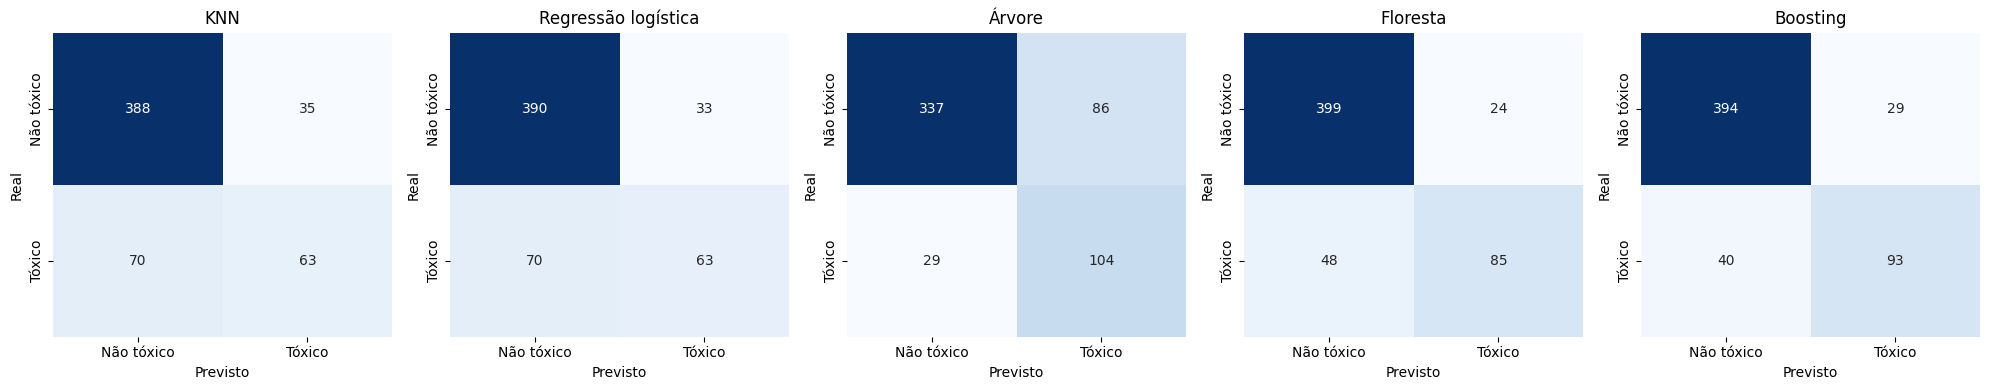

In [57]:
modelos_finais = {
    "KNN":                 melhor_knn,
    "Regressão logística": melhor_logreg,
    "Árvore":              melhor_dtree,
    "Floresta":            melhor_rflorest,
    "Boosting":            melhor_boosting,
}

fig, eixos = plt.subplots(1, len(modelos_finais), figsize=(4 * len(modelos_finais), 4))

for ax, (nome, modelo) in zip(eixos, modelos_finais.items()):
    proba = modelo.predict_proba(X_teste)[:, 1]         
    pred = (proba >= 0.5).astype(int)
    cm = confusion_matrix(Y_teste, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Não tóxico", "Tóxico"], yticklabels=["Não tóxico", "Tóxico"])
    ax.set_title(nome)
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")

plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "matrizes_confusao_modelos.png")
plt.show()

### 9. Conclusão

Esse trabalho avaliou a capacidade de modelos de aprendizado de máquina de prever a toxicidade de nanopartículas a partir de suas propriedades e das condições experimentais, foi utilizado 2.765 medidas de 25 materiais e 621 experimentos, com cerca de 24% de medidas tóxicas. Foram comparados cinco algoritmos com um classificador baseline de referência, todos com pré-processamento e hiperparâmetros otimizados com Optuna.

Todos os modelos superaram o classificador de referência, com PR-AUC DE 0.239. Os modelos baseados em árvores tiveram os melhores resultados no conjunto teste. A diferença entre a floresta aleatória e o gradient boosting é pequena, e ambos ficaram bem acima do KNN e da regressão logística, com a árvore de decisão em posição intermediária. Esse padrão sugere que a relação entre as variáveis e a toxicidade não é linear e que envolve interações entre as variáveis.

Esses resultados devem ser interpretados à luz do protocolo de validação. Como o teste foi separado por experimento, e não por nanopartícula, o mesmo material pode aparecer no treino e no teste, em condições diferentes. O desempenho medido refere-se, portanto, à previsão de novos experimentos de materiais já conhecidos. Essa distinção é relevante porque os descritores do material assumem apenas 24 ou 25 valores distintos, funcionando na prática como identificadores do material, e a taxa de toxicidade varia muito entre eles.

### Referências

MA, Youfu; JIANG, Yu; SU, Houlin; LEI, Jiajia; XIAO, Wenguang; TIAN, Haijun; MA, Yawei; ZHU, Li; LIANG, Yuxi; WANG, Lisheng; YUAN, Mingqing; LIU, Xu. Interpretable machine learning models for predicting the antitumor effects of metal and metal oxide nanomaterials. RSC Advances, v. 15, n. 21, p. 17036-17048, 2025. DOI: 10.1039/D5RA02309B, disponível em [https://pubs.rsc.org/ra/article/15/21/17036/906739/Interpretable-machine-learning-models-for]


#### Interação com IA

Foi utilizado IA para achar o conjunto de dados e para transformar o arquivo de xlsx em csv. Além disso, foi utilizado para fazer as tabelas em Markdown da Secção 3.1.

ANTHROPIC. Conversa compartilhada no Claude. Disponível em: <https://claude.ai/share/bfbff96d-1a0b-4973-b6a5-9b621827c615>. Acesso em: 07 out. 2026